# Predviđanje odlaska zaposlenika u zdravstvu

Cilj je predvidjeti hoće li zaposlenik napustiti posao, na skupu podataka o zaposlenicima jedne zdravstvene ustanove
(1676 redaka, oko 12 % zaposlenika je otišlo).

Usporedit ću logističku regresiju, random forest, MLP i neuronsku mrežu u Kerasu. Zbog neravnoteže klasa gledam
PR-AUC i ROC-AUC, a ne samo accuracy.

## 1. Postavke i učitavanje podataka

In [17]:
import os, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

In [18]:
# učitavanje podataka (lokalno ili s Kagglea)
LOCAL_CSV = "watson_healthcare_modified.csv"
if os.path.exists(LOCAL_CSV):
    file_path = LOCAL_CSV
else:
    import kagglehub
    path = kagglehub.dataset_download("jpmiller/employee-attrition-for-healthcare")
    file_path = os.path.join(path, "watson_healthcare_modified.csv")

df = pd.read_csv(file_path)
print(df.shape)
display(df.head())
df.info()

Using Colab cache for faster access to the 'employee-attrition-for-healthcare' dataset.
(1676, 35)


,EmployeeID,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,...,RelationshipSatisfaction,StandardHours,Shift,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1313919,41,No,Travel_Rarely,1102,Cardiology,1,2,Life Sciences,1,...,1,80,0,8,0,1,6,4,0,5
1,1200302,49,No,Travel_Frequently,279,Maternity,8,1,Life Sciences,1,...,4,80,1,10,3,3,10,7,1,7
2,1060315,37,Yes,Travel_Rarely,1373,Maternity,2,2,Other,1,...,2,80,0,7,3,3,0,0,0,0
3,1272912,33,No,Travel_Frequently,1392,Maternity,3,4,Life Sciences,1,...,3,80,0,8,3,3,8,7,3,0
4,1414939,27,No,Travel_Rarely,591,Maternity,2,1,Medical,1,...,4,80,1,6,3,3,2,2,2,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1676 entries, 0 to 1675
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   EmployeeID                1676 non-null   int64 
 1   Age                       1676 non-null   int64 
 2   Attrition                 1676 non-null   object
 3   BusinessTravel            1676 non-null   object
 4   DailyRate                 1676 non-null   int64 
 5   Department                1676 non-null   object
 6   DistanceFromHome          1676 non-null   int64 
 7   Education                 1676 non-null   int64 
 8   EducationField            1676 non-null   object
 9   EmployeeCount             1676 non-null   int64 
 10  EnvironmentSatisfaction   1676 non-null   int64 
 11  Gender                    1676 non-null   object
 12  HourlyRate                1676 non-null   int64 
 13  JobInvolvement            1676 non-null   int64 
 14  JobLevel                

## 2. Čišćenje podataka

Micanje ID-a, stupaca koji imaju istu vrijednost u svim redovima i duplikata. Ostale značajke ostaju.

In [19]:
# micanje ID-a i konstantnih stupaca
df = df.drop(columns=["EmployeeID"], errors="ignore")

const_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Konstantni stupci:", const_cols)
df = df.drop(columns=const_cols)

# micanje duplikata (nakon micanja ID-a)
print("Dupliciranih redaka:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Attrition i OverTime u 0/1
df["Attrition"] = (df["Attrition"] == "Yes").astype(int)
df["OverTime"] = (df["OverTime"] == "Yes").astype(int)

print("Nedostajućih vrijednosti:", int(df.isna().sum().sum()))
df.info()

Konstantni stupci: ['EmployeeCount', 'Over18', 'StandardHours']
Dupliciranih redaka: 56
Nedostajućih vrijednosti: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1620 non-null   int64 
 1   Attrition                 1620 non-null   int64 
 2   BusinessTravel            1620 non-null   object
 3   DailyRate                 1620 non-null   int64 
 4   Department                1620 non-null   object
 5   DistanceFromHome          1620 non-null   int64 
 6   Education                 1620 non-null   int64 
 7   EducationField            1620 non-null   object
 8   EnvironmentSatisfaction   1620 non-null   int64 
 9   Gender                    1620 non-null   object
 10  HourlyRate                1620 non-null   int64 
 11  JobInvolvement            1620 non-null   int64 
 12  JobLevel        

## 3. Pregled podataka (EDA)

In [20]:
# podjela na one koji su otišli i one koji su ostali
left_df = df[df["Attrition"] == 1]
stayed_df = df[df["Attrition"] == 0]

n = len(df)
print(f"Ukupno: {n}")
print(f"Otišli:  {len(left_df)} ({len(left_df)/n:.1%})")
print(f"Ostali:  {len(stayed_df)} ({len(stayed_df)/n:.1%})")
print(f"Baseline accuracy (uvijek 'ostaje'): {len(stayed_df)/n:.1%}")

Ukupno: 1620
Otišli:  192 (11.9%)
Ostali:  1428 (88.1%)
Baseline accuracy (uvijek 'ostaje'): 88.1%


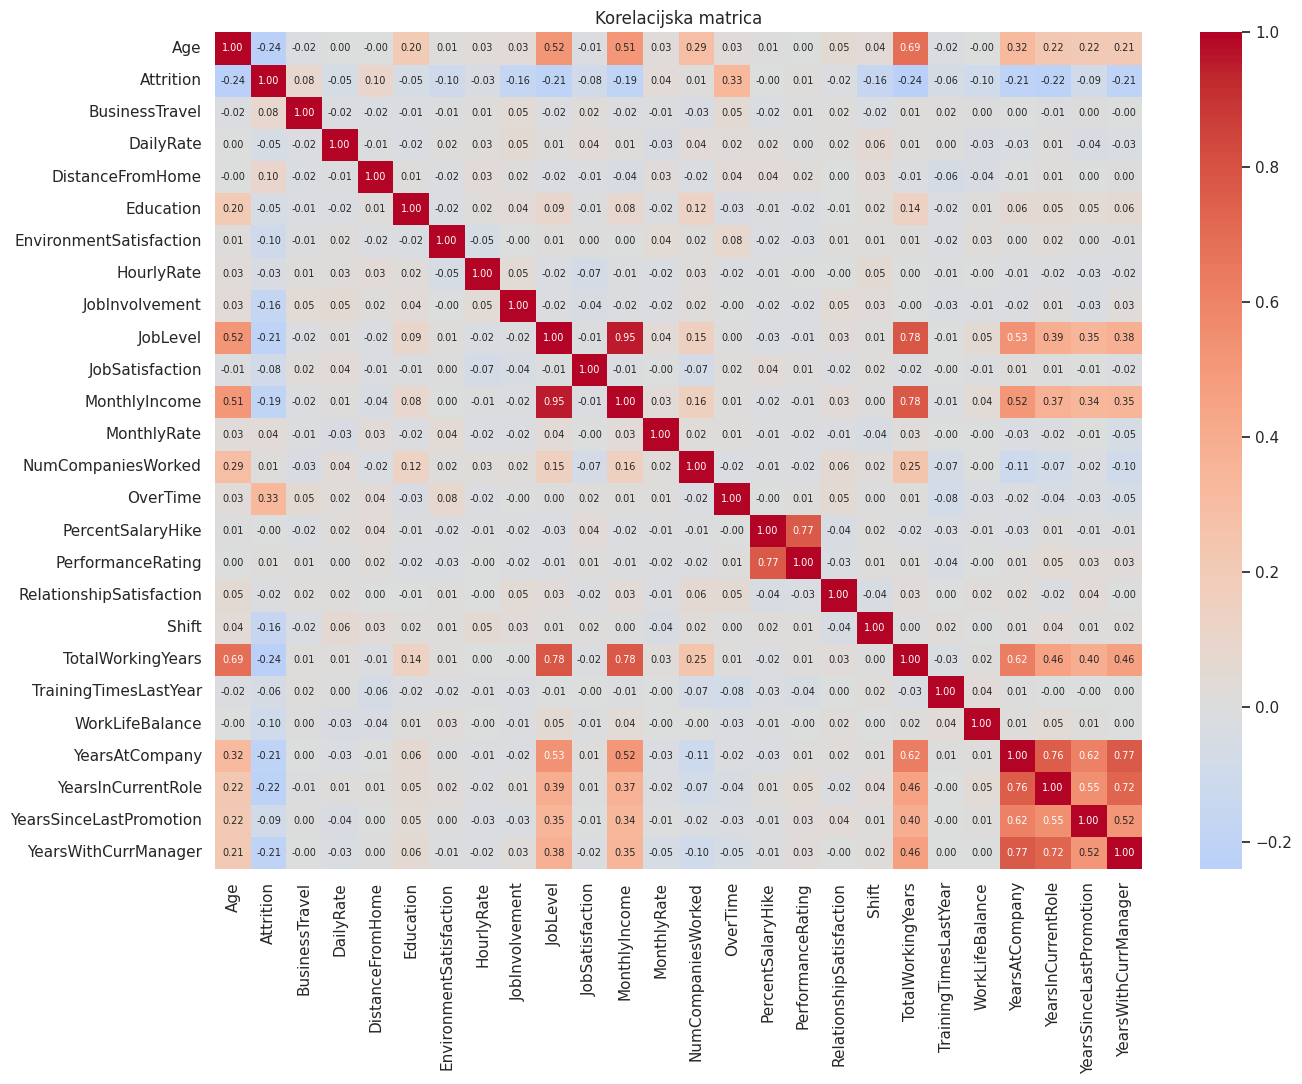

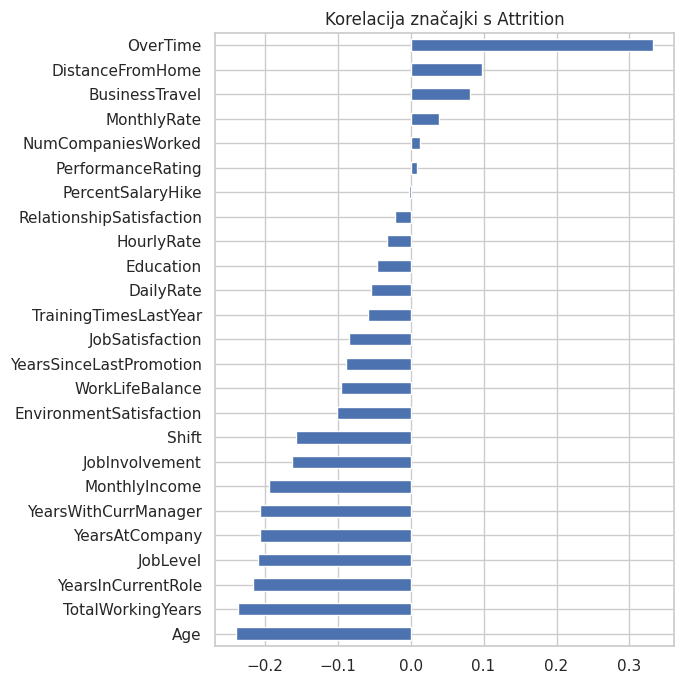

In [21]:
# korelacije (BusinessTravel ima prirodan redoslijed pa ga kodiramo 0-2)
corr_df = df.copy()
corr_df["BusinessTravel"] = corr_df["BusinessTravel"].map(
    {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2})
corr = corr_df.select_dtypes("number").corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Korelacijska matrica")
plt.tight_layout(); plt.show()

corr["Attrition"].drop("Attrition").sort_values().plot(
    kind="barh", figsize=(7, 7), title="Korelacija značajki s Attrition")
plt.tight_layout(); plt.show()

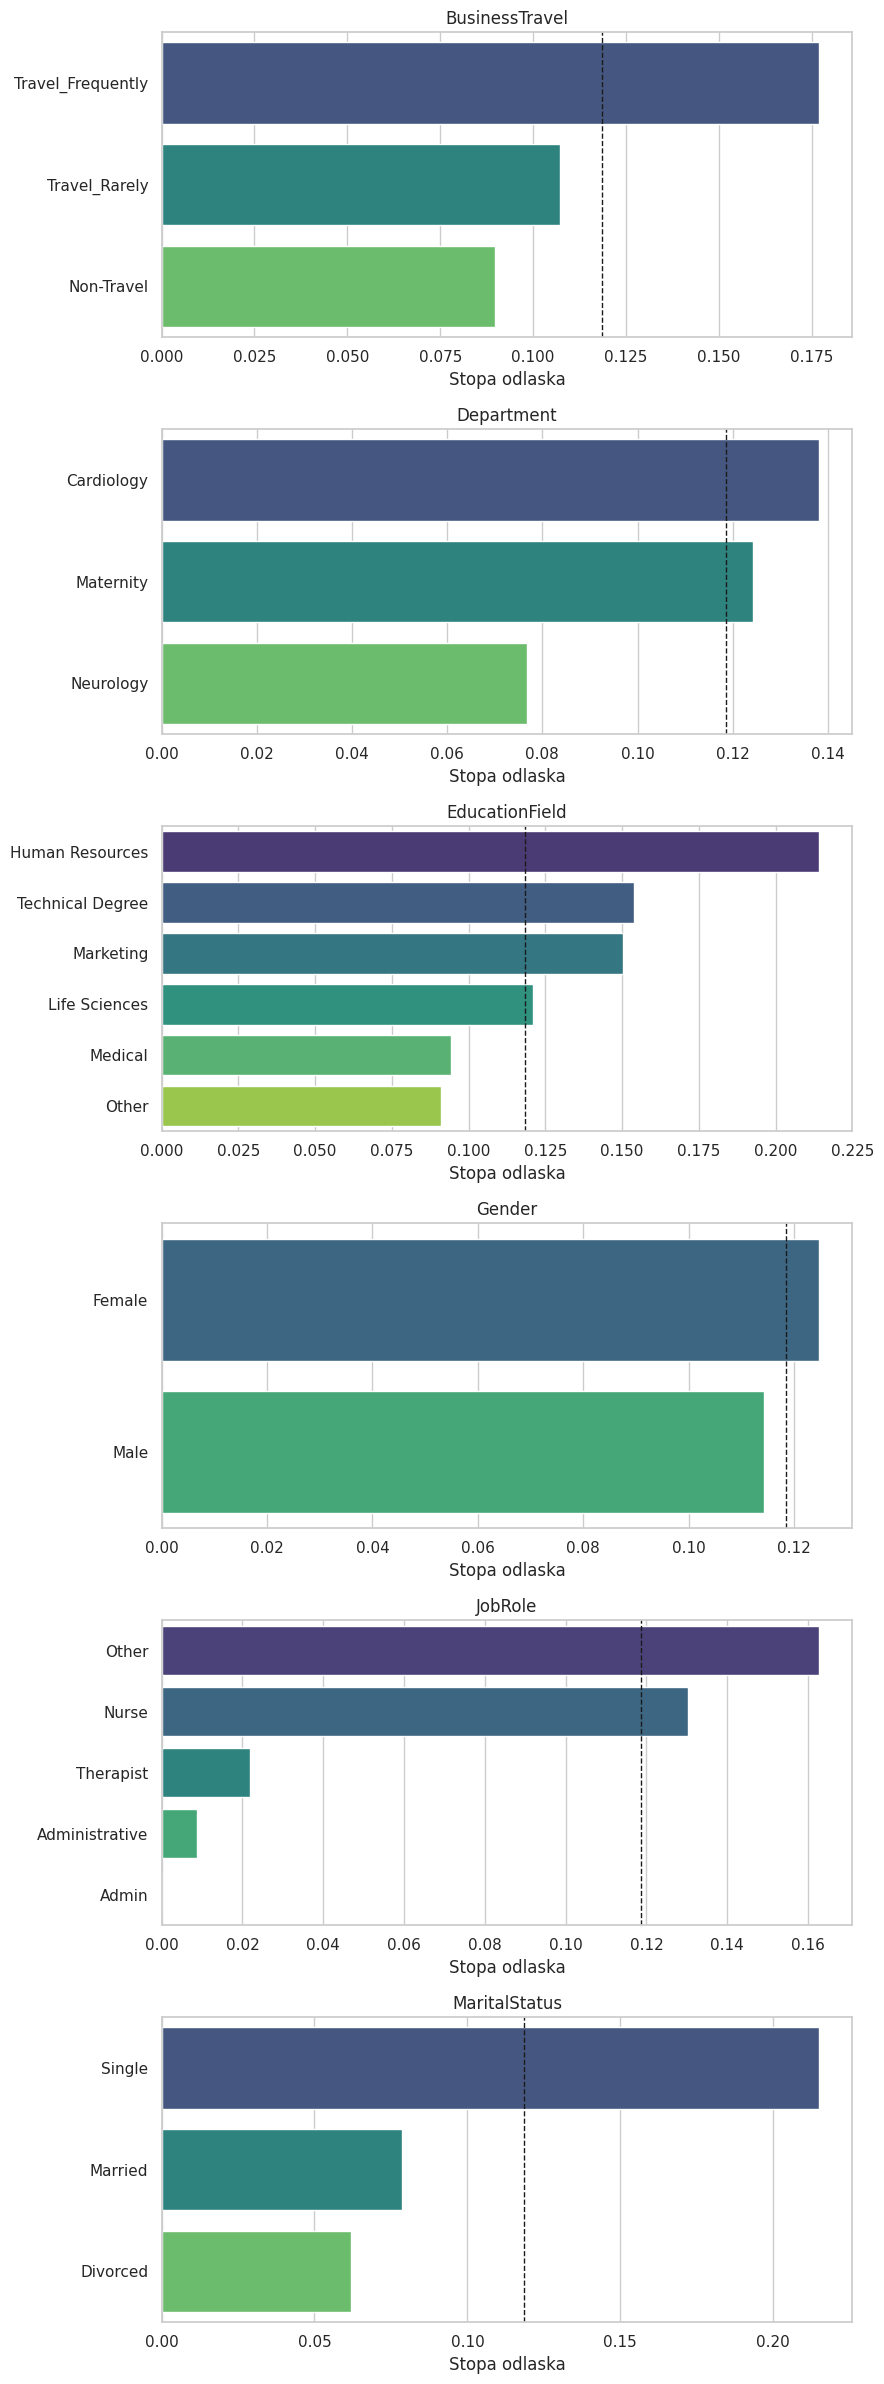

In [22]:
# postotak odlazaka po kategorijama
cat_eda = ["BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus"]
fig, axes = plt.subplots(len(cat_eda), 1, figsize=(9, 4 * len(cat_eda)))
for ax, col in zip(axes, cat_eda):
    rate = df.groupby(col)["Attrition"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, hue=rate.index, legend=False, ax=ax, palette="viridis")
    ax.axvline(df["Attrition"].mean(), color="k", ls="--", lw=1, label="Prosjek")
    ax.set_xlabel("Stopa odlaska"); ax.set_ylabel(""); ax.set_title(col)
plt.tight_layout(); plt.show()

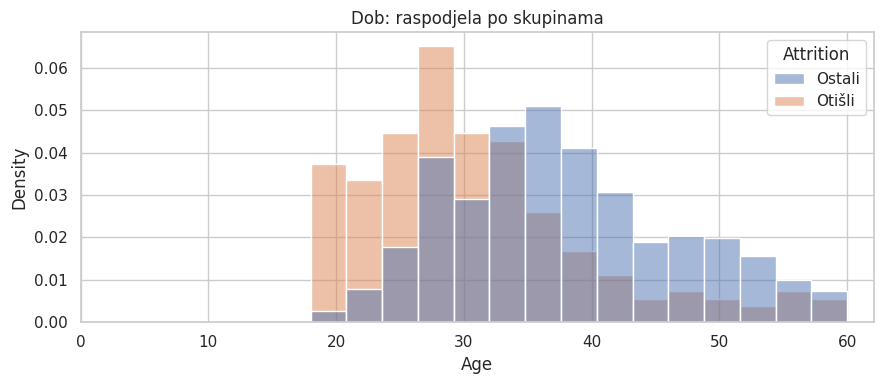

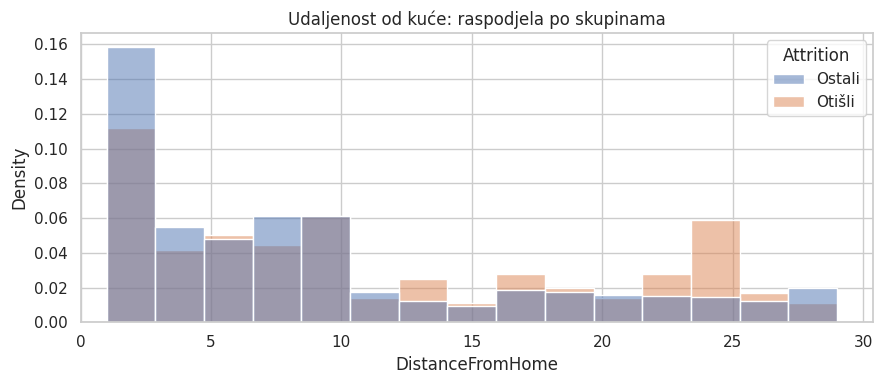

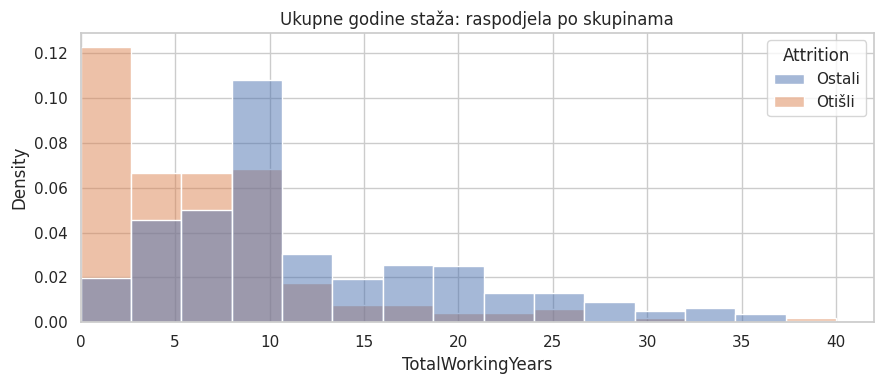

In [23]:
# raspodjele po skupinama (gustoća, jer su skupine različite veličine)
for col, title in [("Age", "Dob"),
                   ("DistanceFromHome", "Udaljenost od kuće"),
                   ("TotalWorkingYears", "Ukupne godine staža")]:
    plt.figure(figsize=(9, 4))
    sns.histplot(data=df, x=col, hue=df["Attrition"].map({0: "Ostali", 1: "Otišli"}),
                 stat="density", common_norm=False, bins=15, alpha=0.5)
    plt.title(f"{title}: raspodjela po skupinama")
    plt.xlim(left=0); plt.tight_layout(); plt.show()

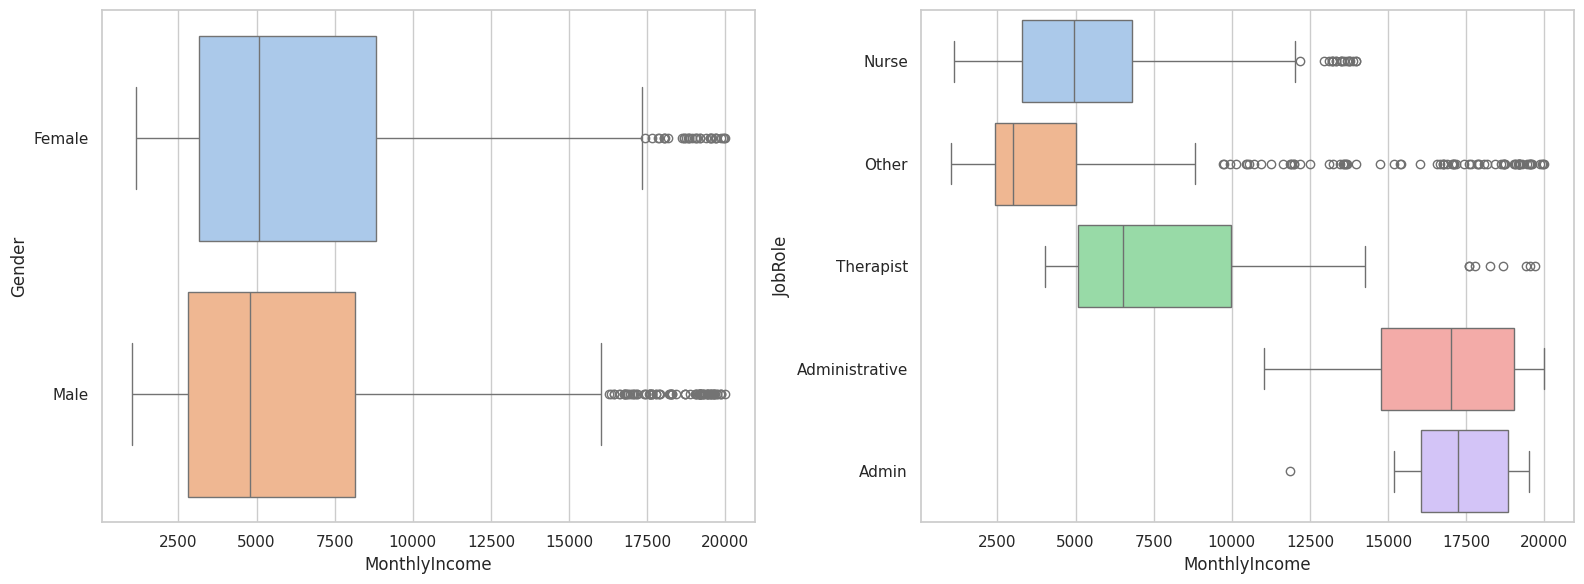

In [24]:
# plaće po spolu i po poslu
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, x="MonthlyIncome", y="Gender", hue="Gender", legend=False, palette="pastel", ax=axes[0])
sns.boxplot(data=df, x="MonthlyIncome", y="JobRole", hue="JobRole", legend=False, palette="pastel", ax=axes[1])
plt.tight_layout(); plt.show()

## 4. Podjela podataka

Podjela na train i test je 75/25, uz isti udio odlazaka u oba dijela. One-hot kodiranje i skaliranje rade se
unutar pipelinea, pa se uče samo na train skupu.

In [25]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline

# True ako se spol ne smije koristiti u modelu
EXCLUDE_SENSITIVE = False
SENSITIVE = ["Gender"]

X = df.drop(columns="Attrition")
y = df["Attrition"]
if EXCLUDE_SENSITIVE:
    X = X.drop(columns=SENSITIVE)

cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

# stratify drži isti udio odlazaka u train i test skupu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)

print("Kategorijske:", cat_cols)
print("Numeričke:", len(num_cols))
print(f"Udio odlazaka, train: {y_train.mean():.3f} ({y_train.sum()}), test: {y_test.mean():.3f} ({y_test.sum()})")

# predobrada: one-hot za kategorije, skaliranje za brojeve
def make_prep():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", MinMaxScaler(), num_cols),
    ])

Kategorijske: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus']
Numeričke: 24
Udio odlazaka, train: 0.119 (144), test: 0.119 (48)


## 5. Modeli

Za neravnotežu klasa logistička regresija i random forest koriste `class_weight`, a MLP (nema `class_weight`) koristi
oversampling. Modele uspoređujem unakrsnom validacijom, a prag odluke biram na njezinim predviđanjima, ne na testu.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, roc_curve)

# svaki model je pipeline: predobrada + model
models = {
    "Logistička regresija": Pipeline([
        ("prep", make_prep()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))]),
    "Slučajne šume": Pipeline([
        ("prep", make_prep()),
        ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                       class_weight="balanced_subsample",
                                       random_state=SEED, n_jobs=-1))]),
    "MLP (1 skriveni sloj)": ImbPipeline([
        ("prep", make_prep()),
        ("ros", RandomOverSampler(random_state=SEED)),
        ("clf", MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=False,
                              max_iter=500, random_state=SEED))]),
}

# 5-struka unakrsna validacija na train skupu
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["roc_auc", "average_precision", "f1"], n_jobs=1)
    cv_rows.append({
        "Model": name,
        "ROC-AUC": f"{s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}",
        "PR-AUC":  f"{s['test_average_precision'].mean():.3f} ± {s['test_average_precision'].std():.3f}",
        "F1 (prag 0.5)": f"{s['test_f1'].mean():.3f} ± {s['test_f1'].std():.3f}",
    })
print(f"5-struka CV na train skupu (baseline PR-AUC = {y_train.mean():.3f})")
display(pd.DataFrame(cv_rows).set_index("Model"))

5-struka CV na train skupu (baseline PR-AUC = 0.119)


,ROC-AUC,PR-AUC,F1 (prag 0.5)
Model,,,
Logistička regresija,0.930 ± 0.014,0.726 ± 0.057,0.585 ± 0.033
Slučajne šume,0.907 ± 0.005,0.640 ± 0.070,0.525 ± 0.072
MLP (1 skriveni sloj),0.915 ± 0.011,0.688 ± 0.065,0.613 ± 0.067


In [27]:
# prag koji daje najbolji F1
def best_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    return float(thr[np.argmax(f1)])

# prag za svaki model iz predviđanja unakrsne validacije (test se ne koristi)
thresholds = {}
for name, pipe in models.items():
    oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    thresholds[name] = best_threshold(y_train, oof)
print({k: round(v, 3) for k, v in thresholds.items()})

{'Logistička regresija': 0.76, 'Slučajne šume': 0.413, 'MLP (1 skriveni sloj)': 0.669}


## 6. Neuronska mreža (Keras)

Mala mreža (oko 5 tisuća parametara) s dropoutom i ranim zaustavljanjem. Koristi iste CV foldove kao ostali modeli,
a rezultat je prosjek 3 pokretanja.

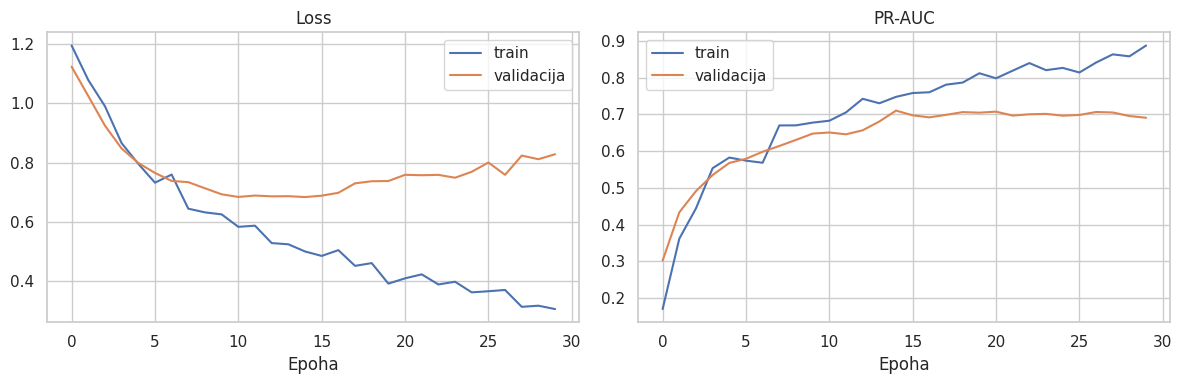

In [28]:
# TensorFlow treba samo ovaj dio
try:
    import tensorflow as tf
    HAS_TF = True
except ImportError:
    HAS_TF = False
    print("TensorFlow nije instaliran, Keras dio se preskače.")

N_SEEDS = 3
keras_proba_test, keras_thr = None, None

if HAS_TF:
    # mreža s dva skrivena sloja
    def build_keras(n_features):
        m = tf.keras.Sequential([
            tf.keras.Input(shape=(n_features,)),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dropout(0.2),
            tf.keras.layers.Dense(1, activation="sigmoid")])
        m.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc")])
        return m

    # treniranje: 20 % podataka ide u validaciju za rano zaustavljanje,
    # klasa odlazaka ima veću težinu zbog neravnoteže
    def fit_keras_predict(X_a, y_a, X_targets, seed):
        tf.keras.utils.set_random_seed(seed)
        X_f, X_v, y_f, y_v = train_test_split(X_a, y_a, test_size=0.2, stratify=y_a, random_state=seed)
        prep = make_prep().fit(X_f)
        Xf, Xv = prep.transform(X_f), prep.transform(X_v)
        y_f, y_v = y_f.to_numpy(), y_v.to_numpy()
        w_pos = (y_f == 0).sum() / (y_f == 1).sum()
        sw_val = np.where(y_v == 1, w_pos, 1.0)
        m = build_keras(Xf.shape[1])
        hist = m.fit(Xf, y_f, validation_data=(Xv, y_v, sw_val), epochs=200, batch_size=32, verbose=0,
                     class_weight={0: 1.0, 1: w_pos},
                     callbacks=[tf.keras.callbacks.EarlyStopping(
                         monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True)])
        return [m.predict(prep.transform(Xt), verbose=0).ravel() for Xt in X_targets], hist

    # isti foldovi kao kod ostalih modela, prag iz njihovih predviđanja
    keras_oof = np.zeros(len(y_train))
    for tr, te in cv.split(X_train, y_train):
        keras_oof[te] = np.mean(
            [fit_keras_predict(X_train.iloc[tr], y_train.iloc[tr], [X_train.iloc[te]], SEED + s)[0][0]
             for s in range(N_SEEDS)], axis=0)
    keras_thr = best_threshold(y_train, keras_oof)

    # konačni model na cijelom train skupu, prosjek 3 pokretanja
    outs = [fit_keras_predict(X_train, y_train, [X_test], SEED + s) for s in range(N_SEEDS)]
    keras_proba_test = np.mean([o[0][0] for o in outs], axis=0)
    hist = outs[0][1]

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validacija")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Epoha"); ax[0].legend()
    ax[1].plot(hist.history["pr_auc"], label="train"); ax[1].plot(hist.history["val_pr_auc"], label="validacija")
    ax[1].set_title("PR-AUC"); ax[1].set_xlabel("Epoha"); ax[1].legend()
    plt.tight_layout(); plt.show()

## 7. Rezultati na test skupu

Test skup se koristi samo ovdje. U matricama zabune redovi su stvarne vrijednosti, a stupci predviđene.

Test skup: 405 uzoraka, 48 odlazaka (baseline PR-AUC = 0.119)


,ROC-AUC,PR-AUC,Prag,Precision,Recall,F1,F1 (prag 0.5)
Model,,,,,,,
Logistička regresija,0.930,0.774,0.760,0.652,0.625,0.638,0.642
Slučajne šume,0.924,0.676,0.413,0.659,0.562,0.607,0.553
MLP (1 skriveni sloj),0.912,0.701,0.669,0.674,0.604,0.637,0.667
Keras DNN (64-32),0.932,0.765,0.736,0.689,0.646,0.667,0.678


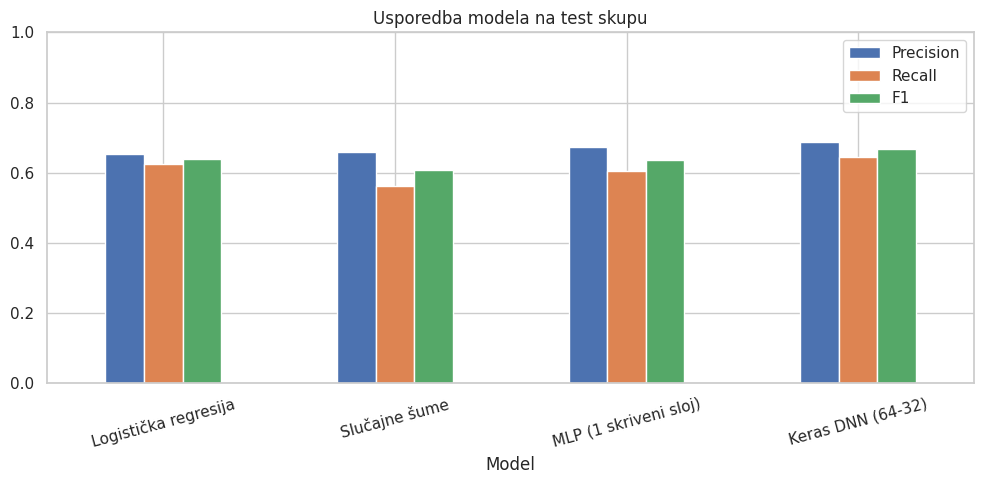

In [29]:
# treniranje na cijelom train skupu i predviđanja na test skupu
proba_test = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    proba_test[name] = pipe.predict_proba(X_test)[:, 1]
final_thr = dict(thresholds)

if keras_proba_test is not None:
    proba_test["Keras DNN (64-32)"] = keras_proba_test
    final_thr["Keras DNN (64-32)"] = keras_thr

# metrike pri odabranom pragu
rows = []
for name, p in proba_test.items():
    thr = final_thr[name]
    pred = (p >= thr).astype(int)
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "Prag": thr,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "F1 (prag 0.5)": f1_score(y_test, (p >= 0.5).astype(int)),
    })
df_results = pd.DataFrame(rows).set_index("Model")
print(f"Test skup: {len(y_test)} uzoraka, {y_test.sum()} odlazaka (baseline PR-AUC = {y_test.mean():.3f})")
display(df_results.round(3))

df_results[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Usporedba modela na test skupu")
plt.ylim(0, 1); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

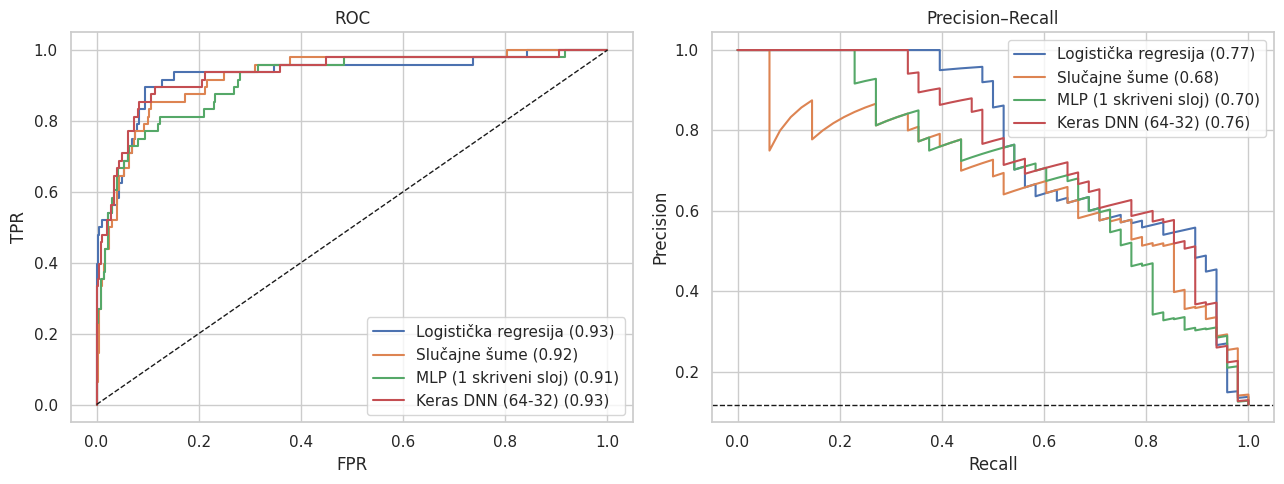

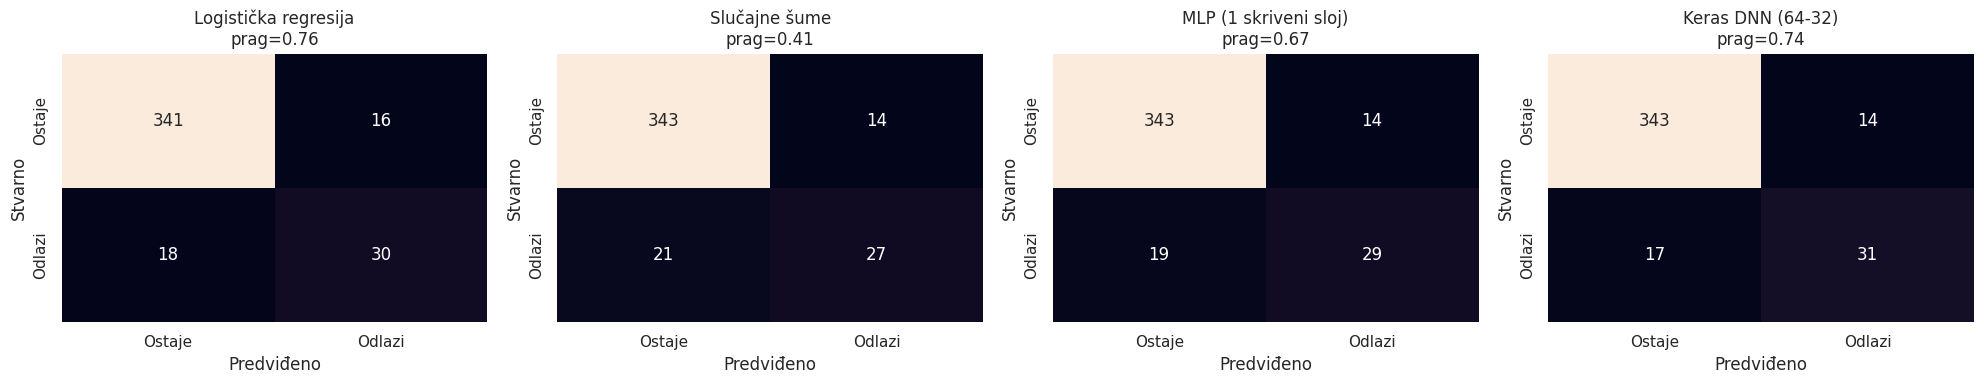


=== Logistička regresija ===
              precision    recall  f1-score   support

      Ostaje       0.95      0.96      0.95       357
      Odlazi       0.65      0.62      0.64        48

    accuracy                           0.92       405
   macro avg       0.80      0.79      0.80       405
weighted avg       0.91      0.92      0.92       405


=== Slučajne šume ===
              precision    recall  f1-score   support

      Ostaje       0.94      0.96      0.95       357
      Odlazi       0.66      0.56      0.61        48

    accuracy                           0.91       405
   macro avg       0.80      0.76      0.78       405
weighted avg       0.91      0.91      0.91       405


=== MLP (1 skriveni sloj) ===
              precision    recall  f1-score   support

      Ostaje       0.95      0.96      0.95       357
      Odlazi       0.67      0.60      0.64        48

    accuracy                           0.92       405
   macro avg       0.81      0.78      0.80 

In [30]:
# ROC i PR krivulje
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.2f})")
    ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_test, p):.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set_title("Precision–Recall")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

# matrice zabune (redovi = stvarno, stupci = predviđeno)
fig, axes = plt.subplots(1, len(proba_test), figsize=(5 * len(proba_test), 4))
axes = np.atleast_1d(axes)
for ax, (name, p) in zip(axes, proba_test.items()):
    pred = (p >= final_thr[name]).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cbar=False, ax=ax,
                xticklabels=["Ostaje", "Odlazi"], yticklabels=["Ostaje", "Odlazi"])
    ax.set_title(f"{name}\nprag={final_thr[name]:.2f}")
    ax.set_xlabel("Predviđeno"); ax.set_ylabel("Stvarno")
plt.tight_layout(); plt.show()

for name, p in proba_test.items():
    print(f"\n=== {name} ===")
    print(classification_report(y_test, (p >= final_thr[name]).astype(int),
                                target_names=["Ostaje", "Odlazi"]))

In [31]:
# bootstrap: razlikuju li se modeli stvarno od logističke regresije
def paired_bootstrap(y, p_ref, p_other, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y = np.asarray(y); pts, diffs = [], []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].sum() == 0:
            continue
        a = average_precision_score(y[idx], p_other[idx])
        b = average_precision_score(y[idx], p_ref[idx])
        pts.append(a); diffs.append(a - b)
    return np.percentile(pts, [2.5, 97.5]), np.mean(diffs), np.percentile(diffs, [2.5, 97.5])

REF = "Logistička regresija"
y_arr = y_test.to_numpy()
rows = []
for name, p in proba_test.items():
    ci, d, dci = paired_bootstrap(y_arr, proba_test[REF], p)
    rows.append({"Model": name,
                 "PR-AUC": round(average_precision_score(y_arr, p), 3),
                 "95% CI": f"[{ci[0]:.3f}, {ci[1]:.3f}]",
                 "Δ vs LR": "—" if name == REF else f"{d:+.3f} [{dci[0]:+.3f}, {dci[1]:+.3f}]",
                 "Značajno": "—" if name == REF else ("da" if dci[0] > 0 or dci[1] < 0 else "ne")})
display(pd.DataFrame(rows).set_index("Model"))

,PR-AUC,95% CI,Δ vs LR,Značajno
Model,,,,
Logistička regresija,0.774,"[0.666, 0.859]",—,—
Slučajne šume,0.676,"[0.540, 0.811]","-0.092 [-0.212, +0.022]",ne
MLP (1 skriveni sloj),0.701,"[0.573, 0.814]","-0.071 [-0.133, -0.009]",da
Keras DNN (64-32),0.765,"[0.645, 0.859]","-0.009 [-0.052, +0.032]",ne


## 8. Važnost značajki

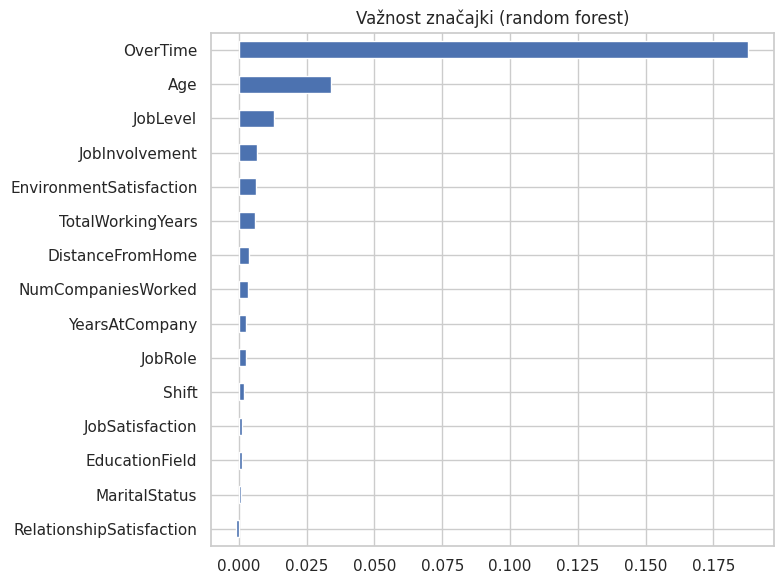

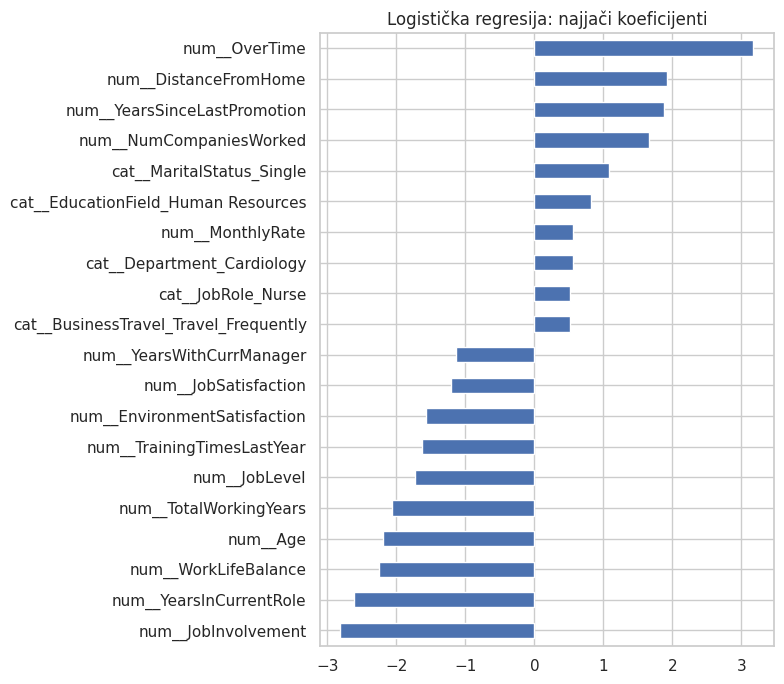

In [32]:
from sklearn.inspection import permutation_importance

# modeli se treniraju i ovdje da ćelija radi i samostalno
for m in models.values():
    m.fit(X_train, y_train)

# koliko pada PR-AUC kad se značajka izmiješa
rf = models["Slučajne šume"]
pi = permutation_importance(rf, X_test, y_test, scoring="average_precision",
                            n_repeats=20, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(15)[::-1].plot(kind="barh", figsize=(8, 6),
                        title="Važnost značajki (random forest)")
plt.tight_layout(); plt.show()

# koeficijenti logističke regresije
lr = models["Logistička regresija"]
names = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_.ravel(), index=names).sort_values()
pd.concat([coef.head(10), coef.tail(10)]).plot(kind="barh", figsize=(8, 7),
        title="Logistička regresija: najjači koeficijenti")
plt.tight_layout(); plt.show()

## 9. Zaključak

* Modele treba uspoređivati po PR-AUC i ROC-AUC, ne po accuracy (88 % se dobije i kad se uvijek predvidi da zaposlenik ostaje).
* Test skup ima samo oko 48 odlazaka, pa male razlike među modelima nisu pouzdane. Ako se intervali preklapaju, razlika nije značajna.
* Prag ovisi o tome što je skuplje: lažni alarm ili propušteni odlazak.
* Skup je demonstracijski (IBM), pa se rezultati ne mogu izravno prenijeti na stvarne podatke.
* Spol, dob i bračni status mogu unijeti pristranost. Za stvarnu primjenu postavi `EXCLUDE_SENSITIVE = True`.